<center><h1>Yu_Stella_HW5</h1></center>
<br>
<br>

Name: Stella Yu
<br>
Github Username: syu35435-cmyk
<br>
USC ID: 3420585291

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn.model_selection as skm
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
df = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, encoding="utf-16")

print(df.shape)
df.head()


(120, 8)


,0,1,2,3,4,5,6,7
0,"35,5",no,yes,no,no,no,no,no
1,"35,9",no,no,yes,yes,yes,yes,no
2,"35,9",no,yes,no,no,no,no,no
3,"36,0",no,no,yes,yes,yes,yes,no
4,"36,0",no,yes,no,no,no,no,no


### (b) Build a decision tree

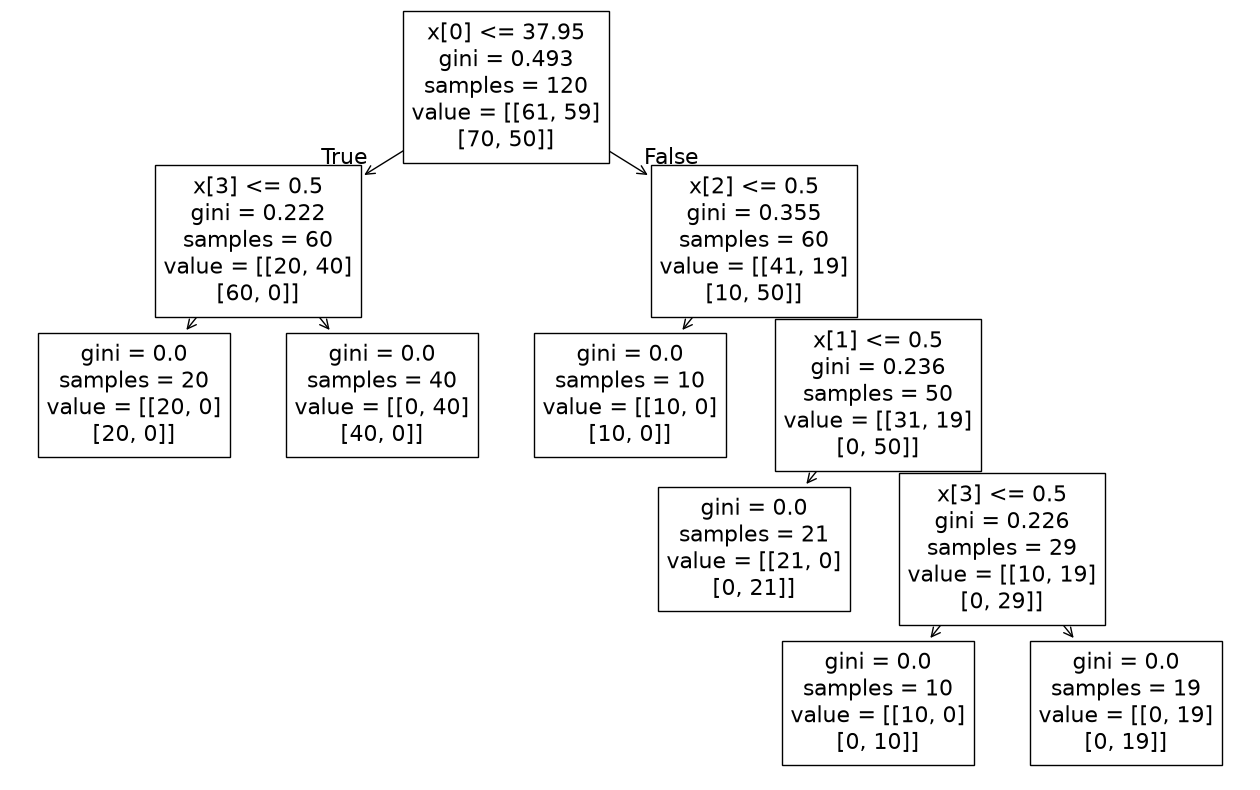

In [3]:
df = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, encoding="utf-16")

df[0] = df[0].str.replace(",", ".").astype(float)
df = df.replace({"yes": 1, "no": 0})

X = df.iloc[:, :6].astype(float)
y = df.iloc[:, 6:8].astype(int)

model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

plt.figure(figsize=(16, 10))
plot_tree(model)
plt.show()



### (c) Convert the decision rules

In [4]:
# Kdnuggets Code in 
# https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
def tree_to_pseudo(tree, feature_names):
    """
    Outputs a decision tree model as if/then pseudocode
    """

    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "  " * depth
        if (threshold[node] != -2):
            print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            if left[node] != -1:
                recurse(left, right, threshold, features, left[node], depth+1)
                print(indent,"} else {")
                if right[node] != -1:
                    recurse(left, right, threshold, features, right[node], depth+1)
                print(indent,"}")
        else:
            print(indent,"return " + str(value[node]))

    recurse(left, right, threshold, features, 0)


feature_names = ["Temperature", "Nausea", "Lumbar Pain","Urine Pushing", "Micturition Pains", "Burning"]

tree_to_pseudo(model, feature_names)


 if ( Temperature <= 37.95000076293945 ) {
   if ( Urine Pushing <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     return [[0. 1.]
 [1. 0.]]
   }
 } else {
   if ( Lumbar Pain <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     if ( Nausea <= 0.5 ) {
       return [[1. 0.]
 [0. 1.]]
     } else {
       if ( Urine Pushing <= 0.5 ) {
         return [[1. 0.]
 [0. 1.]]
       } else {
         return [[0. 1.]
 [0. 1.]]
       }
     }
   }
 }


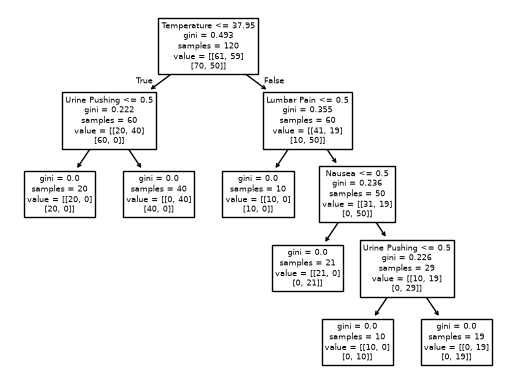

 if ( Temperature <= 37.95000076293945 ) {
   if ( Urine Pushing <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     return [[0. 1.]
 [1. 0.]]
   }
 } else {
   if ( Lumbar Pain <= 0.5 ) {
     return [[1. 0.]
 [1. 0.]]
   } else {
     if ( Nausea <= 0.5 ) {
       return [[1. 0.]
 [0. 1.]]
     } else {
       if ( Urine Pushing <= 0.5 ) {
         return [[1. 0.]
 [0. 1.]]
       } else {
         return [[0. 1.]
 [0. 1.]]
       }
     }
   }
 }


In [5]:
ccp_path = model.cost_complexity_pruning_path(X, y)

kfold = skm.KFold(5, random_state=1, shuffle=True)

grid = skm.GridSearchCV(
    model,
    {"ccp_alpha": ccp_path.ccp_alphas},
    refit=True,
    cv=kfold,
    scoring="accuracy"
)

grid.fit(X, y)

best_ = grid.best_estimator_

plot_tree(best_, feature_names=feature_names)
plt.show()

tree_to_pseudo(best_, feature_names)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
df = pd.read_csv("../data/communities.data", header=None)

train = df.iloc[:1495]
test = df.iloc[1495:]

### (b) Missing values

In [7]:
train = train.replace("?", float("nan"))
test = test.replace("?", float("nan"))

train = train.iloc[:, 5:]
test = test.iloc[:, 5:]

X_train = train.iloc[:, :-1].astype(float)
X_test = test.iloc[:, :-1].astype(float)
y_train = train.iloc[:, -1].astype(float)
y_test = test.iloc[:, -1].astype(float)

imputer = SimpleImputer(strategy="mean").set_output(transform="pandas")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

### (c) Plot a correlation matrix

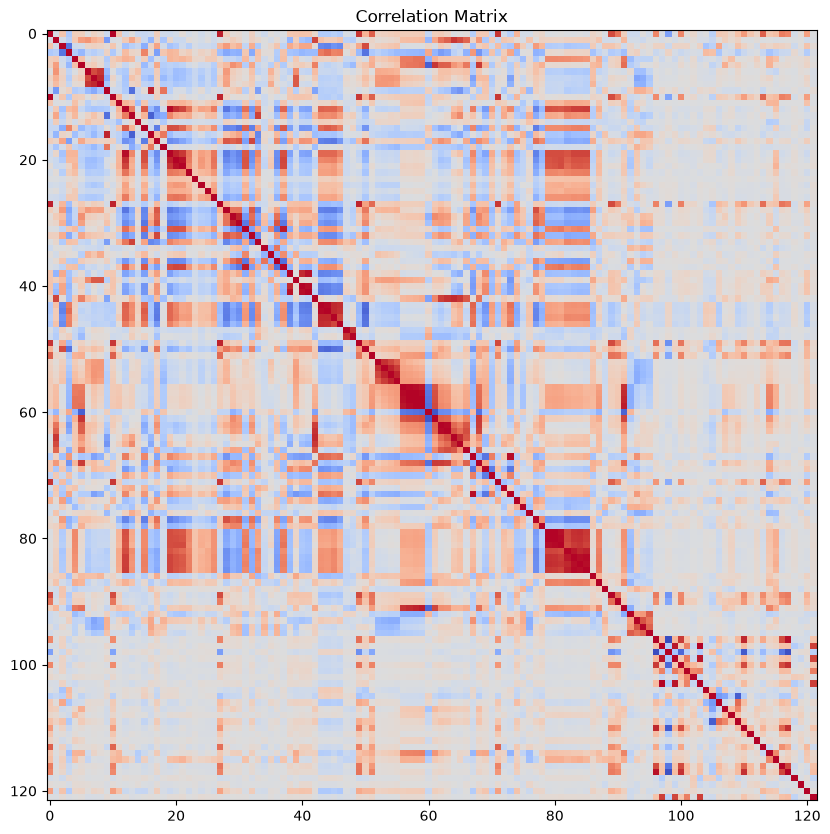

In [8]:
corr = X_train.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
cv = X_train.std() / X_train.mean()
print(cv)

x0      2.241105
x1      0.355800
x2      1.428885
x3      0.330213
x4      1.359100
          ...   
x117    0.743487
x118    0.115739
x119    0.362989
x120    2.552946
x121    0.326026
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

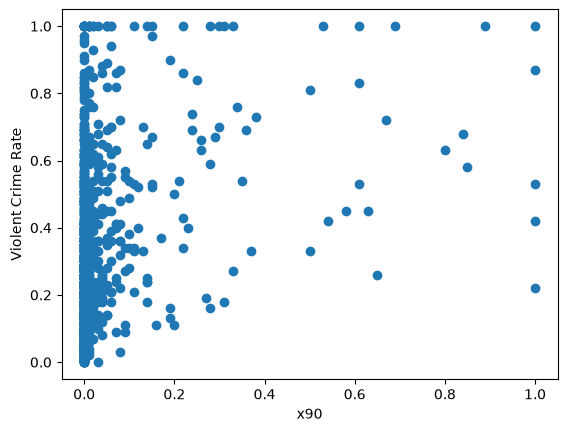

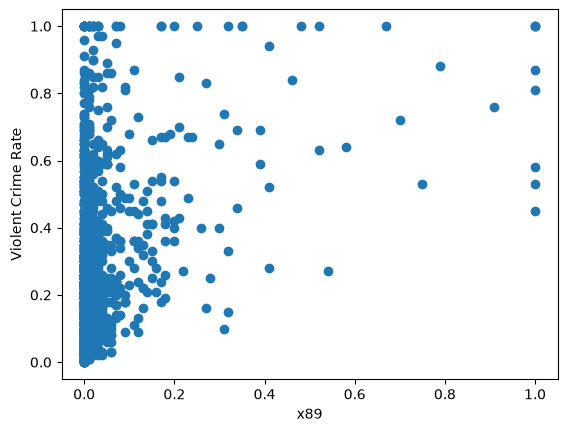

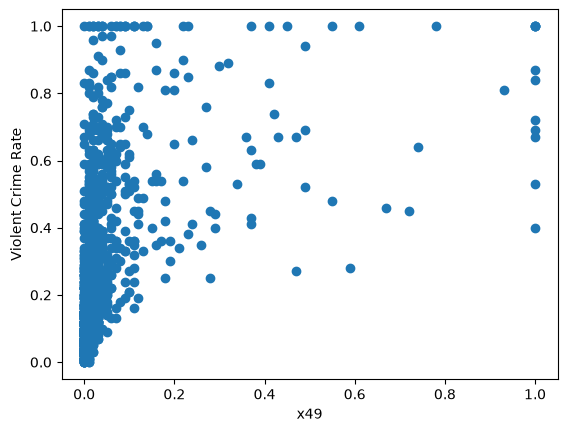

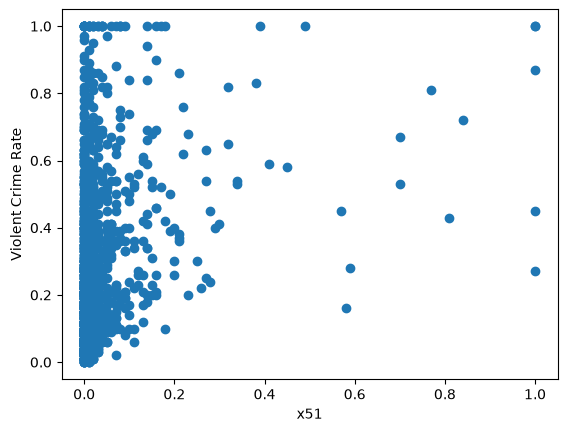

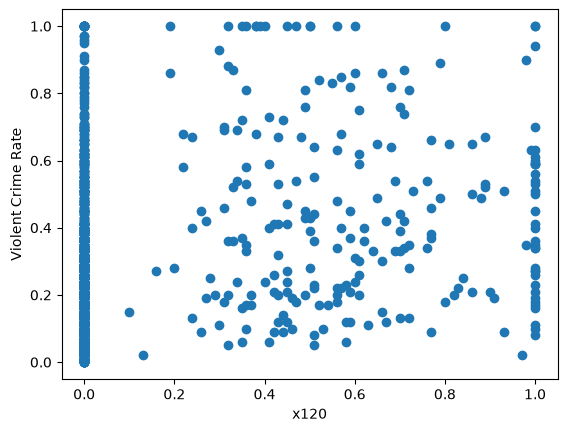

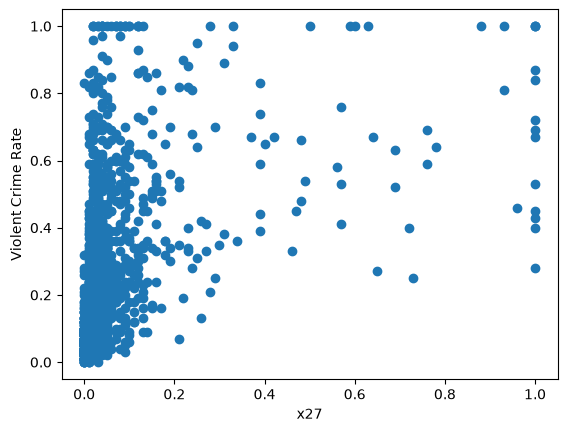

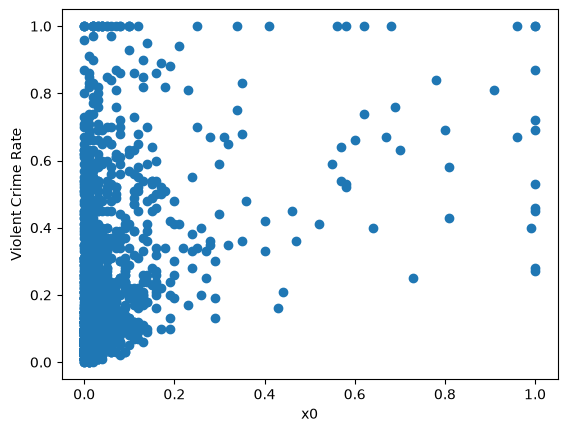

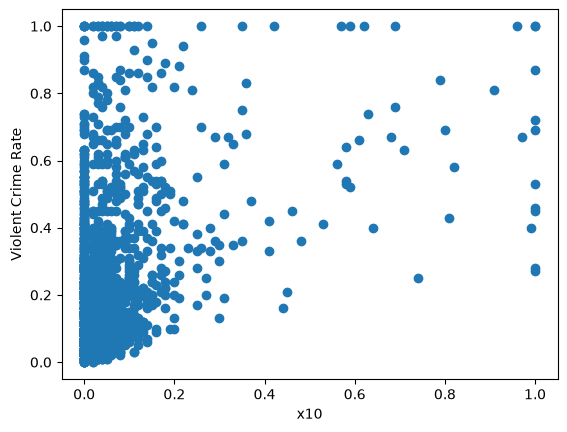

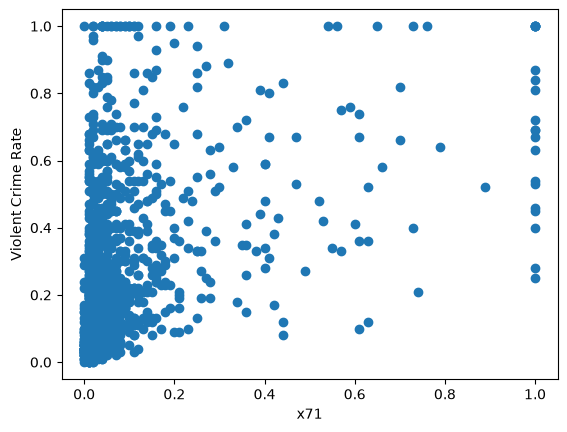

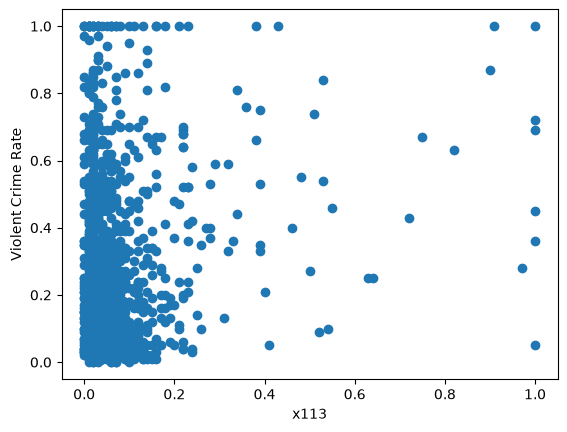

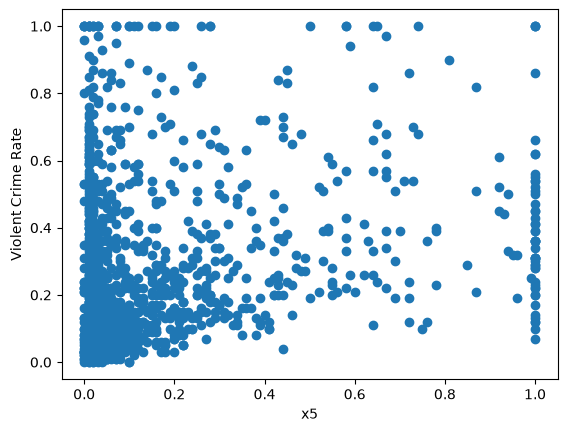

In [10]:
feature_cv = cv.sort_values(ascending=False).head(11)

for feature in feature_cv.index:
    plt.scatter(X_train[feature], y_train)
    plt.xlabel(feature)
    plt.ylabel("Violent Crime Rate")
    plt.show()

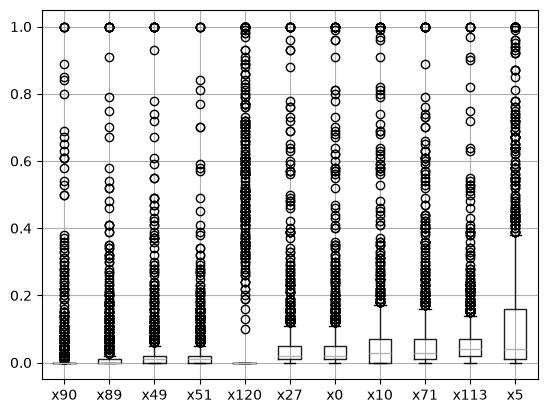

In [11]:
X_train[feature_cv.index].boxplot()
plt.show()

No, we can't draw conclusions about the significance of features just by the scatter plots. The points are too scattered to identify any clear relationships. 

### (f) Fit a linear model

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

test_pred = model.predict(X_test)
test_error = mean_squared_error(y_test, test_pred)

print("Linear Regression Test Error:", test_error)

Linear Regression Test Error: 0.01814197113553008


### (g) Fit a ridge regression model

In [13]:
alphas = np.logspace(-4, 4, 100)

ridge = RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error")
ridge.fit(X_train, y_train)

test_pred = ridge.predict(X_test)
test_error = mean_squared_error(y_test, test_pred)

print("Ridge Regression Test Error:", test_error)

Ridge Regression Test Error: 0.01759961379245254


### (h) Fit a LASSO model

In [14]:
lasso = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso.fit(X_train, y_train)

test_pred = lasso.predict(X_test)
test_error = mean_squared_error(y_test, test_pred)

selected_features = X_train.columns[lasso.coef_ != 0]

print("LASSO Test Error:", test_error)
print("Selected features:", list(selected_features))

LASSO Test Error: 0.01775820921631968
Selected features: ['x2', 'x4', 'x6', 'x7', 'x11', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x28', 'x29', 'x33', 'x34', 'x36', 'x38', 'x39', 'x40', 'x44', 'x45', 'x46', 'x48', 'x49', 'x50', 'x51', 'x55', 'x59', 'x61', 'x63', 'x64', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x82', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x94', 'x99', 'x100', 'x102', 'x104', 'x106', 'x108', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x118', 'x119', 'x120', 'x121']


In [15]:
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

lasso = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso.fit(X_train_scaler, y_train)

test_pred = lasso.predict(X_test_scaler)
test_error = mean_squared_error(y_test, test_pred)

selected_features = X_train.columns[lasso.coef_ != 0]

print("LASSO Test Error:", test_error)
print("Selected features:", list(selected_features))


LASSO Test Error: 0.01780533927686227
Selected features: ['x2', 'x4', 'x6', 'x7', 'x11', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x28', 'x29', 'x33', 'x34', 'x38', 'x39', 'x40', 'x44', 'x45', 'x46', 'x48', 'x49', 'x50', 'x51', 'x53', 'x55', 'x59', 'x61', 'x63', 'x64', 'x67', 'x68', 'x69', 'x71', 'x72', 'x74', 'x75', 'x76', 'x77', 'x78', 'x82', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x94', 'x99', 'x100', 'x102', 'x104', 'x105', 'x106', 'x107', 'x108', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x118', 'x119']


The LASSO model without standardization achieved a test MSE of 0.0177. The LASSO model with standardization achieved a test MSE of 0.0178. The  LASSO model without standardization model achieved slightly better performance, but the difference was very small.

### (i) Fit a PCR model

In [16]:
pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

parameters = {"pca__n_components": range(1, 123)}
grid = GridSearchCV(pcr, parameters, cv=5, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)

test_pred = grid.predict(X_test)
test_error = mean_squared_error(y_test, test_pred)

print("PCR Test Error:", test_error)


PCR Test Error: 0.01839293123038784


### (j) Fit a boosting tree

In [17]:
xgb = XGBRegressor(random_state=42)

parameters = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(xgb, parameters, cv=5, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)

test_pred = grid.predict(X_test)
test_error = mean_squared_error(y_test, test_pred)

print("XGBoost Test Error:", test_error)


XGBoost Test Error: 0.017747461401957192
